# 06. 일기 감정 분석 — 긍정·부정 그래프 + 중립 + 전체 감정 캘린더 (05 수정본)

- KoBERT/KOTE 기존 44개 출력과 학습된 모델은 유지합니다.
- 감정 범주: **긍정**, **부정**, **중립(없음)**. `없음`은 기존 KOTE 레이블의 하나이며 새 분류기를 학습한 것은 아닙니다.
- 긍정·부정 강도는 각각 그룹별 상위 2개 감정 확률 평균으로 계산합니다. 중립 점수는 모델의 `없음` 레이블 확률 평균을 사용합니다. **세 점수의 합이 1일 필요는 없습니다**(다중 레이블 모델).
- 최종 대표 감정이 '중립'인지 판단할 때는 기존의 `NEUTRAL_MIN_SCORE` 임계값 규칙을 유지합니다. 중립 점수와 대표 감정 판정은 서로 다른 지표입니다.
- 날짜별 **긍정 점수 선 그래프**, **부정 점수 선 그래프**로 변경하고 **전체 감정 캘린더**는 그대로 유지합니다.
- 분석 로직 테스트와 최종 일기 테스트 모두 같은 '시험·발표' 예제를 사용합니다.

**11/8 수정 (박상현)**
- 문장 분리: '하지만', '그렇지만'만 남는 조각이 '하다'/'그렇다' 문장으로 분석되던 버그 수정 → 다음 문장 앞에 붙임
- 긍정/부정 점수 방식을 셀 2의 `POLARITY_AGG`로 선택 (`max` 사용: 비교 결과 긍정 판정 12→10일, 반반인 날만 부정으로 바뀌어 그룹 수 불균형 없는 max로 결정)
- 셀 12-1: 같은 일기로 mean과 max 결과 비교 (대표 감정 일수, 평균 점수, 판정이 달라진 날)
- 같은 문장은 한 번만 예측하도록 캐시 추가


In [1]:
# 1. 기본 설정
import re, calendar
from pathlib import Path
from datetime import date

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import Rectangle, Patch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

cwd = Path.cwd()
project_root = cwd.parent if cwd.name == "notebooks" else cwd
model_dir = project_root / "models"
data_dir = project_root / "data"
output_dir = project_root / "outputs"
output_dir.mkdir(exist_ok=True)

for f in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f
        break

plt.rcParams["axes.unicode_minus"] = False

print("project_root:", project_root)
print("font:", plt.rcParams["font.family"])


device: cuda
project_root: e:\박상현 학교\2학년2학기\기계학습\10조_미니프로젝트#1_기계학습[00]\diary_emotion_project
font: ['Malgun Gothic']


In [2]:
# 2. 설정
MODEL_FILE = "kobert_kote_nall_e5.pt"
DIARY_FILE = data_dir / "sample_diary.csv"

THRESHOLD = None
SPLIT_CONNECTIVES = True

# 그룹 강도 계산 시 사용할 상위 세부 감정 개수
GROUP_TOP_K = 2

# 비중립 감정의 강도가 모두 이 값보다 낮으면 중립
NEUTRAL_MIN_SCORE = 0.35

# 긍정/부정 점수 계산 방식
#  "mean": 그룹 점수 평균 (긍정 2그룹 ÷2, 부정 4그룹 ÷4 → 부정이 더 깎임)
#  "max" : 그룹 점수 중 최댓값 (그룹 수와 상관없이 비교)
POLARITY_AGG = "max"


In [3]:
# 3. KOTE 44개 세부 감정 + 대표 감정 그룹
LABELS = [
    '불평/불만','환영/호의','감동/감탄','지긋지긋','고마움','슬픔','화남/분노','존경',
    '기대감','우쭐댐/무시함','안타까움/실망','비장함','의심/불신','뿌듯함','편안/쾌적',
    '신기함/관심','아껴주는','부끄러움','공포/무서움','절망','한심함','역겨움/징그러움',
    '짜증','어이없음','없음','패배/자기혐오','귀찮음','힘듦/지침','즐거움/신남','깨달음',
    '죄책감','증오/혐오','흐뭇함(귀여움/예쁨)','당황/난처','경악','부담/안 내킴','서러움',
    '재미없음','불쌍함/연민','놀람','행복','불안/걱정','기쁨','안심/신뢰'
]

GROUPS = {
    "기쁨·만족": [
        '환영/호의','감동/감탄','고마움','존경','뿌듯함','편안/쾌적','아껴주는',
        '흐뭇함(귀여움/예쁨)','행복','기쁨','즐거움/신남','안심/신뢰'
    ],
    "기대·관심": ['기대감','신기함/관심','깨달음','비장함'],
    "슬픔·실망": [
        '슬픔','안타까움/실망','절망','서러움','불쌍함/연민',
        '패배/자기혐오','죄책감','부끄러움'
    ],
    "분노·불만": [
        '불평/불만','화남/분노','짜증','어이없음','한심함',
        '역겨움/징그러움','증오/혐오','의심/불신','우쭐댐/무시함'
    ],
    "불안·당황": ['공포/무서움','불안/걱정','당황/난처','경악','놀람','부담/안 내킴'],
    "피로·지루함": ['지긋지긋','귀찮음','힘듦/지침','재미없음'],
    "없음": ['없음']
}

DISPLAY_EMOTION = {
    "기쁨·만족": "행복",
    "기대·관심": "기대",
    "슬픔·실망": "슬픔",
    "분노·불만": "분노",
    "불안·당황": "불안",
    "피로·지루함": "피로",
    "없음": "중립"
}

POSITIVE_GROUPS = ["기쁨·만족", "기대·관심"]
NEGATIVE_GROUPS = ["슬픔·실망", "분노·불만", "불안·당황", "피로·지루함"]
NEUTRAL_GROUPS = ["없음"]  # KOTE에 이미 존재하는 중립 성격의 레이블

EMOTION_COLORS = {
    "행복": "#F2C94C",
    "기대": "#5DBB8F",
    "슬픔": "#5B8DEF",
    "분노": "#E5534B",
    "불안": "#9B6FD3",
    "피로": "#8D7B68",
    "중립": "#BDBDBD"
}

GROUP_NAMES = list(GROUPS)
GROUP_IDX = {g: [LABELS.index(e) for e in emotions] for g, emotions in GROUPS.items()}

all_idx = sum(GROUP_IDX.values(), [])
assert sorted(all_idx) == list(range(44)), "44개 감정 매핑을 확인하세요."

print("Positive:", POSITIVE_GROUPS)
print("Negative:", NEGATIVE_GROUPS)
print("Neutral:", NEUTRAL_GROUPS)


Positive: ['기쁨·만족', '기대·관심']
Negative: ['슬픔·실망', '분노·불만', '불안·당황', '피로·지루함']
Neutral: ['없음']


In [4]:
# 4. 최종 KoBERT 모델 불러오기
from kobert_tokenizer import KoBERTTokenizer
from transformers import BertModel

MODEL_NAME = "skt/kobert-base-v1"
tokenizer = KoBERTTokenizer.from_pretrained(MODEL_NAME)

assert tokenizer.encode("한국어 모델을 공유합니다.") == [
    2, 4958, 6855, 2046, 7088, 1050, 7843, 54, 3
], "KoBERT 토크나이저가 정상적으로 로드되지 않았습니다."

class KoBERTMultiLabelClassifier(nn.Module):
    def __init__(self, num_labels=44, dropout=0.2):
        super().__init__()
        self.bert = BertModel.from_pretrained(MODEL_NAME)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask=None, token_type_ids=None):
        out = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        cls_vector = out.last_hidden_state[:, 0, :]
        return self.classifier(self.dropout(cls_vector))

model_path = model_dir / MODEL_FILE

if not model_path.exists():
    raise FileNotFoundError(
        f"모델 파일이 없습니다: {model_path}\n"
        f"models 폴더에 {MODEL_FILE}을 넣어주세요."
    )

ckpt = torch.load(model_path, map_location=device, weights_only=False)
model = KoBERTMultiLabelClassifier().to(device)

if isinstance(ckpt, dict) and "state_dict" in ckpt:
    model.load_state_dict(ckpt["state_dict"])
    TH = THRESHOLD if THRESHOLD is not None else ckpt.get("threshold", 0.6)
    MAX_LENGTH = ckpt.get("max_length", 64)
else:
    model.load_state_dict(ckpt)
    TH = THRESHOLD if THRESHOLD is not None else 0.6
    MAX_LENGTH = 64

model.eval()

print("모델:", MODEL_FILE)
print("threshold:", TH)
print("max_length:", MAX_LENGTH)


c:\Users\hyun0\venvs\kobert\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'XLNetTokenizer'. 
The class this function is called from is 'KoBERTTokenizer'.
c:\Users\hyun0\venvs\kobert\Lib\site-packages\transformers\tokenization_utils_base.py:1601: FutureWarning: `clean_up_tokenization_spaces` was not set. It will be set to `True` by default. This behavior will be depracted in transformers v4.45, and will be then set to `False` by default. For more details check this issue: https://github.com/huggingface/transformers/issues/31884
  warnings.warn(


모델: kobert_kote_nall_e5.pt
threshold: 0.6
max_length: 64


In [5]:
# 5. 여러 문장 감정 확률 예측
_pred_cache = {}

@torch.no_grad()
def _predict_raw(sents, batch_size=32):
    if len(sents) == 0:
        return np.zeros((0, 44), dtype=np.float32)

    outputs = []

    for start in range(0, len(sents), batch_size):
        batch_sents = sents[start:start + batch_size]

        enc = tokenizer(
            batch_sents,
            padding=True,
            truncation=True,
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )
        enc = {k: v.to(device) for k, v in enc.items()}

        logits = model(
            input_ids=enc["input_ids"],
            attention_mask=enc["attention_mask"],
            token_type_ids=enc.get("token_type_ids")
        )

        outputs.append(torch.sigmoid(logits).cpu().numpy())

    return np.concatenate(outputs, axis=0)


def predict_sentences(sents, batch_size=32):
    """같은 문장은 한 번만 예측 (mean/max 비교할 때 시간 절약)"""
    todo = [s for s in dict.fromkeys(sents) if s not in _pred_cache]
    if todo:
        for s, p in zip(todo, _predict_raw(todo, batch_size)):
            _pred_cache[s] = p
    if len(sents) == 0:
        return np.zeros((0, 44), dtype=np.float32)
    return np.stack([_pred_cache[s] for s in sents])


In [6]:
# 6. 문장 분리 개선
# '하지만', '그렇지만'처럼 접속부사만 남는 조각은 문장으로 쓰지 않고 다음 문장 앞에 붙임
CONJ_WORDS = {"하지만", "그렇지만", "그치만", "허지만", "그러하지만"}

def split_sentences(text):
    base_sents = [
        s.strip()
        for s in re.split(r"(?<=[.!?~])\s+|\n+", str(text))
        if s.strip()
    ]

    result = []

    for sent in base_sents:
        if SPLIT_CONNECTIVES:
            # 우선 '~지만' 대조절을 분리
            parts = [p.strip() for p in re.split(r"(?<=지만)\s+", sent) if p.strip()]
        else:
            parts = [sent]

        carry = ""          # 접속부사를 다음 조각에 붙이기 위한 임시 저장
        for part in parts:
            if part in CONJ_WORDS:
                carry = (carry + " " + part).strip()
                continue

            if carry:
                part = carry + " " + part
                carry = ""

            # 불완전한 앞절을 자연스러운 종결형으로 변환
            # 좋았지만 -> 좋았다 / 행복했지만 -> 행복했다 / 피곤하지만 -> 피곤하다
            if part.endswith("지만"):
                part = part[:-2] + "다"

            result.append(part)

        if carry:           # 접속부사만 있고 뒤 문장이 없는 경우
            result.append(carry)

    return result

for t in ["오늘 시험을 잘 봐서 뿌듯했지만 다른 발표가 걱정되고 너무 피곤하다.",
          "시험을 망쳤다. 하지만 친구가 위로해줘서 괜찮았다. 그렇지만 내일이 걱정된다."]:
    print(split_sentences(t))


['오늘 시험을 잘 봐서 뿌듯했다', '다른 발표가 걱정되고 너무 피곤하다.']
['시험을 망쳤다.', '하지만 친구가 위로해줘서 괜찮았다.', '그렇지만 내일이 걱정된다.']


In [7]:
# 7. 그룹별 강도 계산 개선
def calculate_group_strengths(probs, top_k=GROUP_TOP_K):
    '''
    기존: 문장마다 그룹 안의 최고 확률 1개 사용
    개선: 문장마다 그룹 안의 상위 k개 확률 평균 사용

    한 개의 튀는 감정 확률이 그룹 전체를 과도하게 대표하는 현상을 줄인다.
    '''
    group_sentence_scores = {}
    group_strength = {}

    for group, idx in GROUP_IDX.items():
        values = probs[:, idx]
        k = min(top_k, values.shape[1])

        sorted_values = np.sort(values, axis=1)
        sentence_scores = sorted_values[:, -k:].mean(axis=1)

        group_sentence_scores[group] = sentence_scores
        group_strength[group] = float(sentence_scores.mean())

    return group_sentence_scores, group_strength


In [8]:
# 8. 하루 일기 분석
def polarity_score(strength, groups, agg=None):
    """그룹 점수들 → 긍정 또는 부정 점수 하나 (POLARITY_AGG: mean / max)"""
    vals = [strength[g] for g in groups]
    return float(np.max(vals) if (agg or POLARITY_AGG) == "max" else np.mean(vals))

def analyze_text(text, agg=None):
    sents = split_sentences(text)
    probs = predict_sentences(sents)

    if len(probs) == 0:
        raise ValueError("분석할 문장이 없습니다.")

    picked = probs >= TH
    mean_probs = probs.mean(axis=0)

    group_sentence_scores, group_strength = calculate_group_strengths(probs)

    # Positive / Negative는 각각 내부 그룹 평균 -> 최종 50:50 비교
    positive_score = polarity_score(group_strength, POSITIVE_GROUPS, agg)
    negative_score = polarity_score(group_strength, NEGATIVE_GROUPS, agg)

    # KOTE의 기존 "없음" 확률: 긍정/부정 점수와 독립적이며 합이 1이 아님
    neutral_score = float(group_strength["없음"])

    valence = positive_score - negative_score

    non_neutral_max = max(
        max(group_strength[g] for g in POSITIVE_GROUPS),
        max(group_strength[g] for g in NEGATIVE_GROUPS)
    )

    # 1단계: Positive / Negative
    # 2단계: 선택된 극성 안에서 대표 감정 결정
    if non_neutral_max < NEUTRAL_MIN_SCORE:
        main_group = "없음"
    elif positive_score >= negative_score:
        main_group = max(
            POSITIVE_GROUPS,
            key=lambda g: group_strength[g]
        )
    else:
        main_group = max(
            NEGATIVE_GROUPS,
            key=lambda g: group_strength[g]
        )

    main_emotion = DISPLAY_EMOTION[main_group]

    # 각 극성 내부에서 가장 강한 감정
    positive_main_group = max(
        POSITIVE_GROUPS,
        key=lambda g: group_strength[g]
    )

    negative_main_group = max(
        NEGATIVE_GROUPS,
        key=lambda g: group_strength[g]
    )

    positive_emotion = DISPLAY_EMOTION[positive_main_group]
    negative_emotion = DISPLAY_EMOTION[negative_main_group]

    # 세부 감정 Top 5
    top_idx = mean_probs.argsort()[::-1]
    top_emotions = [LABELS[i] for i in top_idx[:5]]

    sent_rows = []

    for k, sentence in enumerate(sents):
        order = probs[k].argsort()[::-1]

        # 화면이 너무 복잡해지지 않도록 threshold 이상 중 Top 5
        selected = [
            f"{LABELS[i]} {probs[k, i]:.2f}"
            for i in order
            if picked[k, i]
        ][:5]

        sentence_group_strength = {
            g: float(group_sentence_scores[g][k])
            for g in GROUP_NAMES
        }

        pos_sentence = polarity_score(sentence_group_strength, POSITIVE_GROUPS, agg)
        neg_sentence = polarity_score(sentence_group_strength, NEGATIVE_GROUPS, agg)

        sentence_max = max(
            max(sentence_group_strength[g] for g in POSITIVE_GROUPS),
            max(sentence_group_strength[g] for g in NEGATIVE_GROUPS)
        )

        if sentence_max < NEUTRAL_MIN_SCORE:
            sentence_group = "없음"
        elif pos_sentence >= neg_sentence:
            sentence_group = max(
                POSITIVE_GROUPS,
                key=lambda g: sentence_group_strength[g]
            )
        else:
            sentence_group = max(
                NEGATIVE_GROUPS,
                key=lambda g: sentence_group_strength[g]
            )

        sent_rows.append({
            "sentence": sentence,
            "main_emotion": DISPLAY_EMOTION[sentence_group],
            "positive_score": round(pos_sentence, 3),
            "negative_score": round(neg_sentence, 3),
            "neutral_score": round(sentence_group_strength["없음"], 3),
            "emotions": ", ".join(selected) if selected else "없음"
        })

    day = {
        "n_sent": len(sents),
        "positive_score": round(positive_score, 3),
        "negative_score": round(negative_score, 3),
        "neutral_score": round(neutral_score, 3),
        "valence": round(float(valence), 3),
        "positive_emotion": positive_emotion,
        "negative_emotion": negative_emotion,
        "main_group": main_group,
        "main_emotion": main_emotion,
        "top_emotions": ", ".join(top_emotions)
    }

    for g in GROUP_NAMES:
        day[f"s_{g}"] = round(group_strength[g], 3)

    return day, sent_rows, mean_probs


In [9]:
# 9. 분석 로직 테스트 — 시험·발표 공통 예제
# 공통 비교 예제: 분석 로직 테스트와 최종 일기 입력에서 같은 문장을 사용
COMPARISON_EXAMPLE = "오늘 시험을 잘 봐서 뿌듯했지만 다른 발표가 걱정되고 너무 피곤하다."

examples = [COMPARISON_EXAMPLE]

for text in examples:
    day, rows, _ = analyze_text(text)

    print("\n문장:", text)
    print("대표 감정:", day["main_emotion"])
    print("Positive:", day["positive_score"], "|", day["positive_emotion"])
    print("Negative:", day["negative_score"], "|", day["negative_emotion"])
    print("Valence:", day["valence"])
    print("세부 Top5:", day["top_emotions"])

    for row in rows:
        print(
            " -",
            row["sentence"],
            "→",
            row["main_emotion"],
            f"(P {row['positive_score']:.3f} / N {row['negative_score']:.3f})"
        )
        print("   세부:", row["emotions"])



문장: 오늘 시험을 잘 봐서 뿌듯했지만 다른 발표가 걱정되고 너무 피곤하다.
대표 감정: 행복
Positive: 0.578 | 행복
Negative: 0.504 | 피로
Valence: 0.074
세부 Top5: 힘듦/지침, 기쁨, 행복, 즐거움/신남, 고마움
 - 오늘 시험을 잘 봐서 뿌듯했다 → 행복 (P 0.979 / N 0.192)
   세부: 기쁨 0.98, 행복 0.98, 고마움 0.96, 즐거움/신남 0.94, 뿌듯함 0.84
 - 다른 발표가 걱정되고 너무 피곤하다. → 피로 (P 0.248 / N 0.816)
   세부: 힘듦/지침 0.91, 불안/걱정 0.73, 지긋지긋 0.72, 짜증 0.70, 귀찮음 0.64


In [10]:
# 10. 일기 데이터 불러오기
if not DIARY_FILE.exists():
    raise FileNotFoundError(f"일기 파일이 없습니다: {DIARY_FILE}")

diary = pd.read_csv(DIARY_FILE, encoding="utf-8-sig")
diary["date"] = pd.to_datetime(diary["date"]).dt.date

diary = (
    diary
    .sort_values("date")
    .drop_duplicates("date", keep="last")
    .reset_index(drop=True)
)

print("일기 수:", len(diary))
print(diary["date"].min(), "~", diary["date"].max())
diary.head()


일기 수: 24
2026-10-01 ~ 2026-10-31


,date,text
0,2026-10-01,오늘부터 10월이다. 날씨가 선선해져서 산책하기 좋았다. 저녁에 친구랑 맛있는 걸 ...
1,2026-10-02,수업이 많아서 조금 피곤했다. 그래도 과제를 미리 끝내서 마음이 편하다.
2,2026-10-03,공휴일이라 늦잠을 잤다. 하루 종일 집에만 있었는데 좀 지루했다.
3,2026-10-05,알바에 손님이 너무 많아서 정신이 없었다. 실수까지 해서 혼나서 속상했다.
4,2026-10-06,동아리 사람들을 오랜만에 만났다. 다들 반갑게 맞아줘서 고마웠다. 이야기를 많이 해...


In [11]:
# 11. 하루 코멘트
def daily_comment(r):
    emotion = r["main_emotion"]
    positive = r["positive_score"]
    negative = r["negative_score"]

    if emotion == "행복":
        return "긍정적인 감정이 더 강하게 나타난 하루예요. 좋았던 순간을 기억해두세요."

    if emotion == "기대":
        return "앞으로의 일에 대한 기대와 관심이 비교적 강하게 나타난 하루예요."

    if emotion == "피로":
        return "피로와 지침이 많이 나타난 하루예요. 충분한 휴식을 챙겨보세요."

    if emotion == "불안":
        return "걱정과 불안 표현이 많이 나타난 하루예요."

    if emotion == "분노":
        return "속상하거나 화가 나는 감정이 강하게 나타난 하루예요."

    if emotion == "슬픔":
        return "슬픔이나 실망과 관련된 표현이 많이 나타난 하루예요."

    if emotion == "중립":
        return "감정 변화가 비교적 잔잔한 하루였어요."

    if positive >= negative:
        return "힘든 감정도 있었지만 긍정적인 감정이 조금 더 높았어요."

    return "힘든 감정이 조금 더 높았던 하루예요."


In [12]:
# 12. 전체 일기 분석 + CSV 저장
def build_daily_outputs():
    day_rows = []
    sent_rows = []

    for _, row in diary.iterrows():
        day_result, sentence_result, _ = analyze_text(row["text"])

        day_rows.append({
            "date": row["date"],
            "text": row["text"],
            **day_result
        })

        for s in sentence_result:
            sent_rows.append({
                "date": row["date"],
                **s
            })

    daily_df = pd.DataFrame(day_rows)
    daily_df["comment"] = daily_df.apply(daily_comment, axis=1)
    sentence_df = pd.DataFrame(sent_rows)

    daily_df.to_csv(
        output_dir / "diary_daily_balanced_v2.csv",
        index=False,
        encoding="utf-8-sig"
    )

    sentence_df.to_csv(
        output_dir / "diary_sentences_balanced_v2.csv",
        index=False,
        encoding="utf-8-sig"
    )

    return daily_df, sentence_df

daily, sentences = build_daily_outputs()

daily[
    [
        "date",
        "positive_score",
        "positive_emotion",
        "negative_score",
        "negative_emotion",
        "neutral_score",
        "main_emotion",
        "valence",
        "top_emotions"
    ]
].head()


,date,positive_score,positive_emotion,negative_score,negative_emotion,neutral_score,main_emotion,valence,top_emotions
0,2026-10-01,0.928,행복,0.235,피로,0.447,행복,0.693,"행복, 기쁨, 즐거움/신남, 편안/쾌적, 뿌듯함"
1,2026-10-02,0.631,행복,0.718,피로,0.400,피로,-0.087,"힘듦/지침, 편안/쾌적, 귀찮음, 안심/신뢰, 아껴주는"
2,2026-10-03,0.197,기대,0.907,피로,0.446,피로,-0.710,"힘듦/지침, 지긋지긋, 재미없음, 짜증, 귀찮음"
3,2026-10-05,0.152,기대,0.835,분노,0.107,분노,-0.683,"짜증, 화남/분노, 안타까움/실망, 당황/난처, 불평/불만"
4,2026-10-06,0.959,행복,0.229,불안,0.339,행복,0.729,"기쁨, 고마움, 행복, 즐거움/신남, 감동/감탄"


In [13]:
# 12-1. 긍정/부정 점수 방식 비교: mean vs max (같은 일기, 같은 모델)
rows = []
for _, r in diary.iterrows():
    for agg in ["mean", "max"]:
        d, _, _ = analyze_text(r["text"], agg=agg)
        rows.append({"date": r["date"], "agg": agg, "P": d["positive_score"],
                     "N": d["negative_score"], "대표": d["main_emotion"]})
cmp = pd.DataFrame(rows)

print("[대표 감정 일수]")
print(cmp.pivot_table(index="대표", columns="agg", values="date", aggfunc="count", fill_value=0)
         .reindex(["행복", "기대", "슬픔", "분노", "불안", "피로", "중립"]).fillna(0).astype(int))
print("\n[평균 점수]")
print(cmp.groupby("agg")[["P", "N"]].mean().round(3))

pos_days = cmp.pivot(index="date", columns="agg", values="대표")
print("\n[긍정 판정 일수] mean:", pos_days["mean"].isin(["행복", "기대"]).sum(),
      "/ max:", pos_days["max"].isin(["행복", "기대"]).sum(), "/ 전체:", len(pos_days))
print("\n[판정이 달라진 날]")
diff = pos_days[pos_days["mean"] != pos_days["max"]]
print(diff if len(diff) else "없음")


[대표 감정 일수]
agg  max  mean
대표            
행복     8    10
기대     2     2
슬픔     1     1
분노     3     2
불안     2     2
피로     8     7
중립     0     0

[평균 점수]
          P      N
agg               
max   0.565  0.594
mean  0.437  0.460

[긍정 판정 일수] mean: 12 / max: 10 / 전체: 24

[판정이 달라진 날]
agg        max mean
date               
2026-10-02  피로   행복
2026-10-27  분노   행복


In [14]:
# 13. 특정 연/월 데이터 선택
def get_month_data(year, month):
    md = daily[
        [
            d.year == year and d.month == month
            for d in daily["date"]
        ]
    ].copy()

    return md.sort_values("date").reset_index(drop=True)

last = daily["date"].max()
SELECT_YEAR = last.year
SELECT_MONTH = last.month

print("기본 표시 월:", SELECT_YEAR, SELECT_MONTH)
print("해당 월 일기 수:", len(get_month_data(SELECT_YEAR, SELECT_MONTH)))


기본 표시 월: 2026 10
해당 월 일기 수: 24


In [15]:
# 14. 캘린더 공통 그리기 함수
def draw_month_calendar(
    year,
    month,
    value_column,
    emotion_column,
    title,
    filename,
    mode="emotion"
):
    md = get_month_data(year, month)
    by_date = md.set_index("date")

    weeks = calendar.Calendar(firstweekday=0).monthdatescalendar(year, month)

    fig, ax = plt.subplots(
        figsize=(10, 1.5 + 1.25 * len(weeks))
    )

    for c, name in enumerate("월화수목금토일"):
        ax.text(
            c + 0.5,
            -0.3,
            name,
            ha="center",
            va="center",
            fontsize=11,
            color="#D33" if c == 6 else "#36C" if c == 5 else "#333"
        )

    for r, week in enumerate(weeks):
        for c, d in enumerate(week):
            inside = d.month == month
            has = inside and d in by_date.index

            if not inside:
                facecolor = "white"
                alpha = 1.0
            elif not has:
                facecolor = "#F5F5F5"
                alpha = 1.0
            else:
                emotion = by_date.loc[d, emotion_column]
                score = float(by_date.loc[d, value_column])

                if mode == "emotion":
                    facecolor = EMOTION_COLORS[emotion]
                    alpha = 0.85
                else:
                    facecolor = EMOTION_COLORS[emotion]
                    alpha = 0.20 + 0.70 * np.clip(score, 0, 1)

            ax.add_patch(
                Rectangle(
                    (c + 0.04, r + 0.04),
                    0.92,
                    0.92,
                    facecolor=facecolor,
                    alpha=alpha,
                    edgecolor="#DDD"
                )
            )

            if inside:
                ax.text(
                    c + 0.1,
                    r + 0.2,
                    str(d.day),
                    fontsize=10,
                    color="#222" if has else "#AAA",
                    fontweight="bold" if has else "normal"
                )

            if has:
                emotion = by_date.loc[d, emotion_column]
                score = float(by_date.loc[d, value_column])

                ax.text(
                    c + 0.5,
                    r + 0.55,
                    emotion,
                    ha="center",
                    va="center",
                    fontsize=9,
                    fontweight="bold"
                )

                if mode != "emotion":
                    ax.text(
                        c + 0.5,
                        r + 0.80,
                        f"{score:.2f}",
                        ha="center",
                        va="center",
                        fontsize=7
                    )

    ax.set_xlim(0, 7)
    ax.set_ylim(len(weeks), -0.6)
    ax.axis("off")
    ax.set_title(f"{year}년 {month}월 {title}", fontsize=15, pad=12)

    plt.tight_layout()

    fig.savefig(
        output_dir / filename,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()


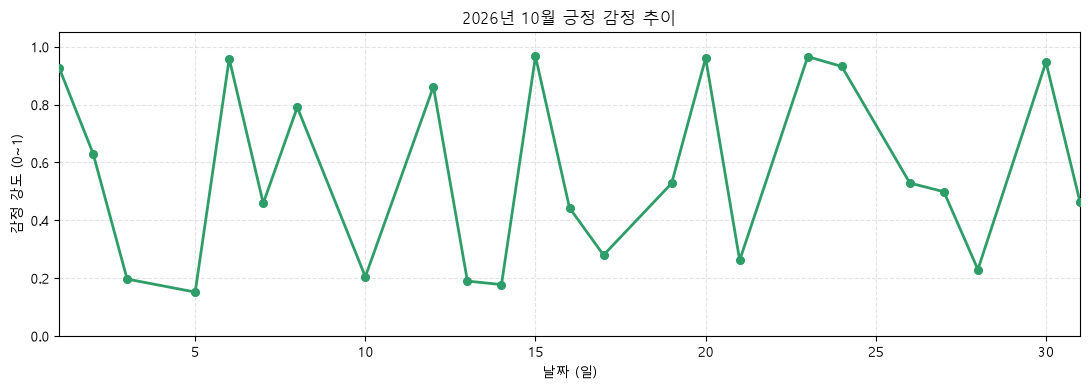

In [16]:
# 15. 한 달 긍정 점수 그래프 (날짜별)
def plot_month_score_graph(year, month, score_column, title, color, filename):
    md = get_month_data(year, month)
    fig, ax = plt.subplots(figsize=(11, 4))

    if not md.empty:
        days = np.array([d.day for d in md["date"]], dtype=int)
        scores = md[score_column].astype(float).to_numpy()
        ax.plot(days, scores, marker="o", markersize=5, linewidth=2, color=color)
        ax.scatter(days, scores, color=color, s=30, zorder=3)
    else:
        ax.text(0.5, 0.5, "해당 월에 작성된 일기가 없습니다.",
                ha="center", va="center", transform=ax.transAxes)

    ax.set_xlim(1, calendar.monthrange(year, month)[1])
    ax.set_ylim(0, 1.05)
    ax.set_xlabel("날짜 (일)")
    ax.set_ylabel("감정 강도 (0~1)")
    ax.set_title(f"{year}년 {month}월 {title}")
    ax.grid(True, linestyle="--", alpha=0.35)
    fig.tight_layout()
    fig.savefig(output_dir / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_positive_graph(year, month):
    plot_month_score_graph(year, month, "positive_score", "긍정 감정 추이", "#2E9D68",
                           f"graph_positive_{year}_{month:02d}.png")

plot_positive_graph(SELECT_YEAR, SELECT_MONTH)


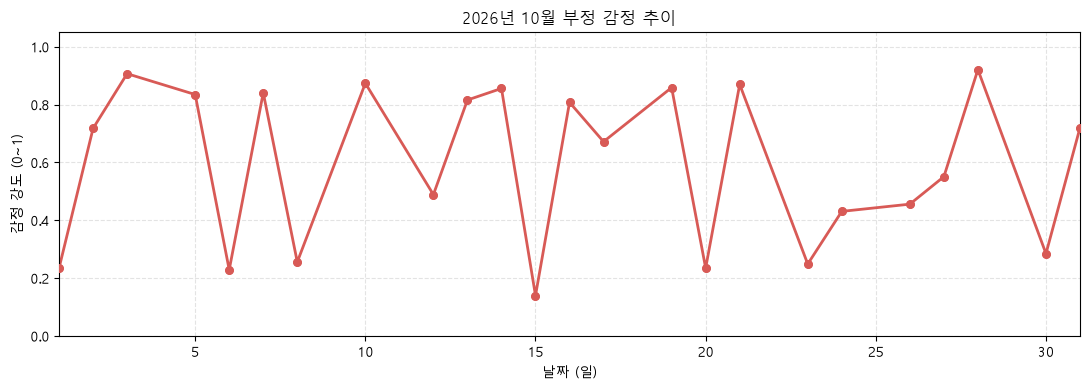

In [17]:
# 16. 한 달 부정 점수 그래프 (날짜별)
def plot_negative_graph(year, month):
    plot_month_score_graph(year, month, "negative_score", "부정 감정 추이", "#D85A56",
                           f"graph_negative_{year}_{month:02d}.png")

plot_negative_graph(SELECT_YEAR, SELECT_MONTH)


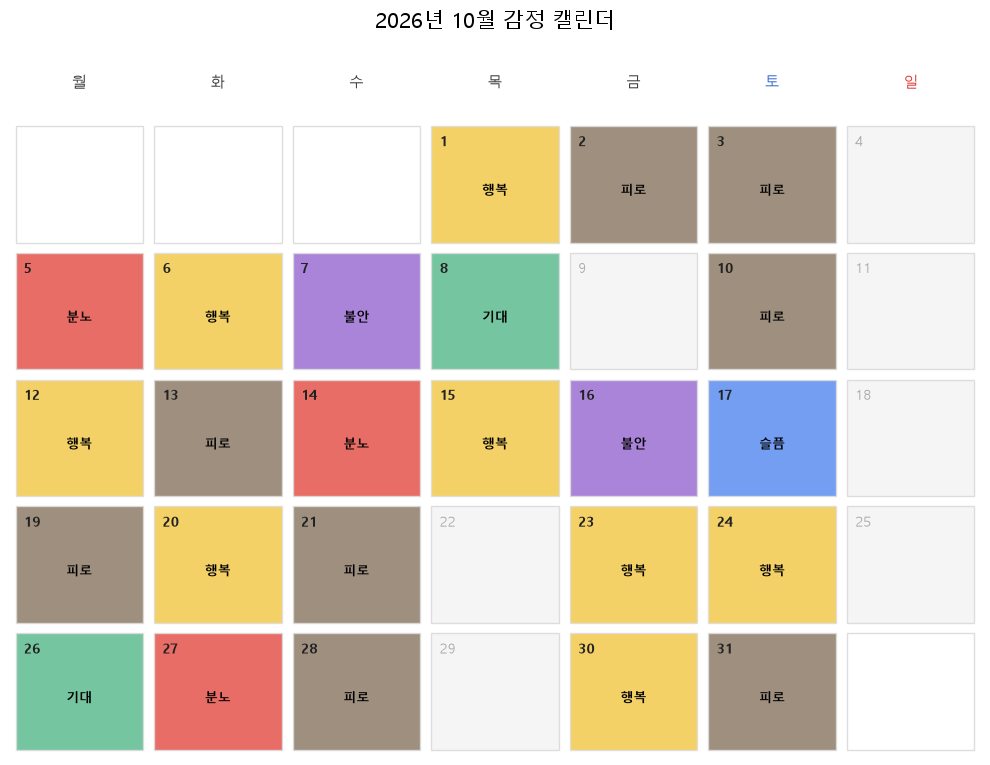

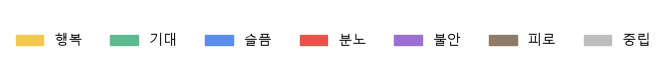

In [18]:
# 17. 한 달 전체 감정 캘린더
def plot_emotion_calendar(year, month):
    draw_month_calendar(
        year=year,
        month=month,
        value_column="valence",
        emotion_column="main_emotion",
        title="감정 캘린더",
        filename=f"calendar_emotion_{year}_{month:02d}.png",
        mode="emotion"
    )

    handles = [
        Patch(color=EMOTION_COLORS[e], label=e)
        for e in ["행복", "기대", "슬픔", "분노", "불안", "피로", "중립"]
    ]

    # 범례는 별도로 확인 가능
    fig, ax = plt.subplots(figsize=(8, 0.8))
    ax.axis("off")
    ax.legend(
        handles=handles,
        loc="center",
        ncol=7,
        frameon=False
    )
    plt.show()

plot_emotion_calendar(SELECT_YEAR, SELECT_MONTH)


In [19]:
# 18. 지정한 달의 그래프 2개 + 전체 감정 캘린더
def show_month_summary(year, month):
    print(f"{year}년 {month}월")
    print("1) 긍정 감정 그래프")
    plot_positive_graph(year, month)
    print("2) 부정 감정 그래프")
    plot_negative_graph(year, month)
    print("3) 전체 감정 캘린더 (중립 포함)")
    plot_emotion_calendar(year, month)

# 사용 예시: show_month_summary(2026, 10)


In [20]:
# 19. 오늘 일기 쓰기 + 분석 결과 자동 갱신
def write_diary(text, day=None, save=True, refresh=True):
    global diary, daily, sentences

    day = day or date.today()
    result, sent_rows, _ = analyze_text(text)

    print(f"[{day}]")

    for s in sent_rows:
        print(f"- {s['sentence']}")
        print(
            f"  → 대표: {s['main_emotion']} | "
            f"P {s['positive_score']:.3f} / N {s['negative_score']:.3f} / 중립 {s['neutral_score']:.3f}"
        )
        print(f"  → 세부: {s['emotions']}")

    print("\nPositive:", result["positive_score"], "|", result["positive_emotion"])
    print("Negative:", result["negative_score"], "|", result["negative_emotion"])
    print("Neutral (없음):", result["neutral_score"])
    print("대표 감정:", result["main_emotion"])
    print("Valence:", result["valence"])
    print("세부 Top5:", result["top_emotions"])

    temp = {**result}
    temp["comment"] = daily_comment(temp)
    print("코멘트:", temp["comment"])

    if not save:
        return temp

    old = pd.read_csv(DIARY_FILE, encoding="utf-8-sig")
    old = old[old["date"] != str(day)]

    new_row = pd.DataFrame([{
        "date": str(day),
        "text": text
    }])

    old = pd.concat([old, new_row], ignore_index=True).sort_values("date")

    old.to_csv(
        DIARY_FILE,
        index=False,
        encoding="utf-8-sig"
    )

    print("\n일기 저장 완료")

    if refresh:
        diary = pd.read_csv(DIARY_FILE, encoding="utf-8-sig")
        diary["date"] = pd.to_datetime(diary["date"]).dt.date
        diary = diary.sort_values("date").reset_index(drop=True)

        daily, sentences = build_daily_outputs()

        print("분석 결과 자동 갱신 완료")

        show_month_summary(day.year, day.month)

    return temp


In [21]:
# 20. 최종 테스트 — 비교 예제 동일
result = write_diary(
    "오늘 시험을 잘 봐서 뿌듯했지만 다른 발표가 걱정되고 너무 피곤하다.",
    save=False
)


[2026-11-09]
- 오늘 시험을 잘 봐서 뿌듯했다
  → 대표: 행복 | P 0.979 / N 0.192 / 중립 0.111
  → 세부: 기쁨 0.98, 행복 0.98, 고마움 0.96, 즐거움/신남 0.94, 뿌듯함 0.84
- 다른 발표가 걱정되고 너무 피곤하다.
  → 대표: 피로 | P 0.248 / N 0.816 / 중립 0.212
  → 세부: 힘듦/지침 0.91, 불안/걱정 0.73, 지긋지긋 0.72, 짜증 0.70, 귀찮음 0.64

Positive: 0.578 | 행복
Negative: 0.504 | 피로
Neutral (없음): 0.161
대표 감정: 행복
Valence: 0.074
세부 Top5: 힘듦/지침, 기쁨, 행복, 즐거움/신남, 고마움
코멘트: 긍정적인 감정이 더 강하게 나타난 하루예요. 좋았던 순간을 기억해두세요.
